# Phân tích Dữ liệu Churn và Retention (EDA)
Notebook này thực hiện việc Khám phá Dữ liệu (EDA) trên tập dữ liệu `real_phase1_output.csv`.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập hiển thị đồ thị
plt.style.use('ggplot')
sns.set_theme(style="whitegrid")

# Tải dữ liệu
df = pd.read_csv('data/real_phase1_output.csv')
df.head()

,customer_id,name,tenure_months,contract_type,payment_method,monthly_fee,total_charges,churn_risk_score,ltv
0,3668-QPYBK,Vũ Cường,2,Month-to-month,Mailed check,1292400.0,2595600.0,0.825514,7.576562e+06
1,9237-HQITU,Trần Trang,2,Month-to-month,Electronic check,1696800.0,3639600.0,0.772477,1.319340e+07
2,9305-CDSKC,Huỳnh Minh,8,Month-to-month,Electronic check,2391600.0,19692000.0,0.733870,3.946724e+07
3,7892-POOKP,Đỗ Nam,28,Month-to-month,Electronic check,2515200.0,73105200.0,0.866718,8.940821e+07
4,0280-XJGEX,Đặng Dung,49,Month-to-month,Bank transfer (automatic),2488800.0,120871200.0,0.738013,1.477089e+08


## 1. Thông tin cơ bản về tập dữ liệu

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1869 entries, 0 to 1868
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       1869 non-null   object 
 1   name              1869 non-null   object 
 2   tenure_months     1869 non-null   int64  
 3   contract_type     1869 non-null   object 
 4   payment_method    1869 non-null   object 
 5   monthly_fee       1869 non-null   float64
 6   total_charges     1869 non-null   float64
 7   churn_risk_score  1869 non-null   float64
 8   ltv               1869 non-null   float64
dtypes: float64(4), int64(1), object(4)
memory usage: 131.5+ KB


In [4]:
df.describe()

,tenure_months,monthly_fee,total_charges,churn_risk_score,ltv
count,1869.000000,1.869000e+03,1.869000e+03,1869.000000,1.869000e+03
mean,17.979133,1.786592e+06,3.676311e+07,0.822774,5.020568e+07
std,19.531123,5.919853e+05,4.537975e+07,0.072831,4.823448e+07
min,1.000000,4.524000e+05,4.524000e+05,0.700206,1.933434e+06
25%,2.000000,1.347600e+06,3.228000e+06,0.759146,1.529024e+07
50%,10.000000,1.911600e+06,1.688520e+07,0.821147,3.131605e+07
75%,29.000000,2.260800e+06,5.595120e+07,0.885311,7.077206e+07
max,72.000000,2.840400e+06,2.084352e+08,0.949589,2.388356e+08


In [5]:
# Kiểm tra giá trị bị thiếu (Missing values)
df.isnull().sum()

customer_id         0
name                0
tenure_months       0
contract_type       0
payment_method      0
monthly_fee         0
total_charges       0
churn_risk_score    0
ltv                 0
dtype: int64

## 2. Phân tích các biến số học

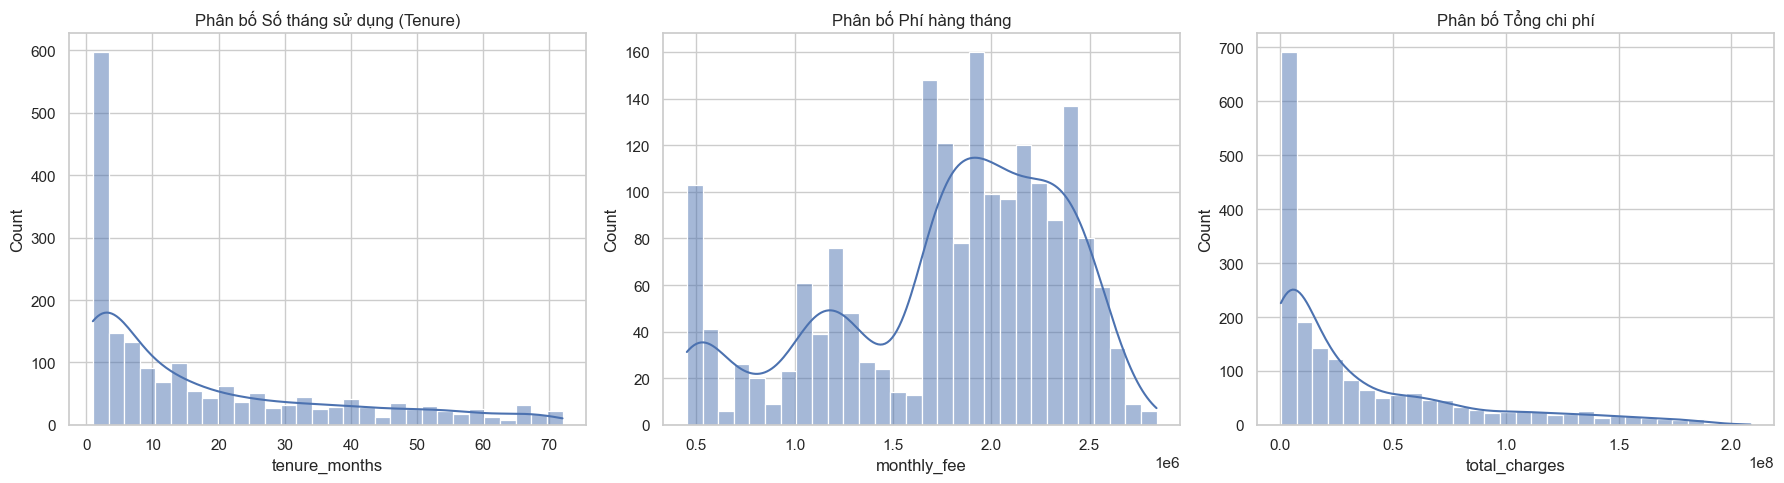

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['tenure_months'], bins=30, kde=True, ax=axes[0])
axes[0].set_title('Phân bố Số tháng sử dụng (Tenure)')

sns.histplot(df['monthly_fee'], bins=30, kde=True, ax=axes[1])
axes[1].set_title('Phân bố Phí hàng tháng')

sns.histplot(df['total_charges'], bins=30, kde=True, ax=axes[2])
axes[2].set_title('Phân bố Tổng chi phí')

plt.tight_layout()
plt.show()

## 3. Phân tích điểm rủi ro rời mạng (Churn Risk Score) và LTV

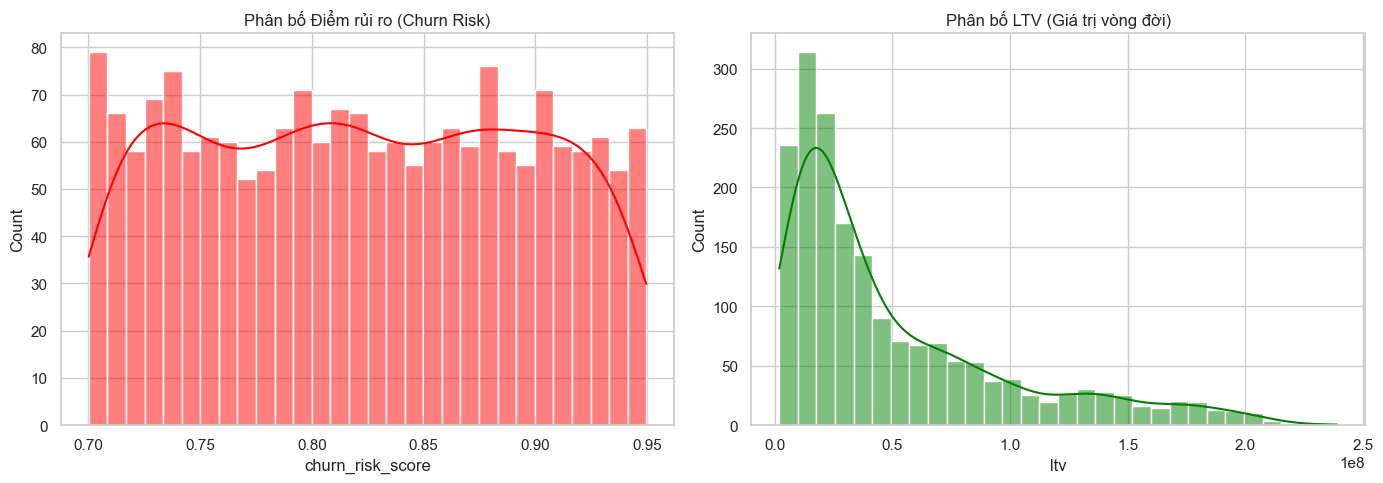

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['churn_risk_score'], bins=30, kde=True, color='red', ax=axes[0])
axes[0].set_title('Phân bố Điểm rủi ro (Churn Risk)')

sns.histplot(df['ltv'], bins=30, kde=True, color='green', ax=axes[1])
axes[1].set_title('Phân bố LTV (Giá trị vòng đời)')

plt.tight_layout()
plt.show()

## 4. Phân tích các biến phân loại (Categorical variables)

D:\Temp\ipykernel_2508\3904770555.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='contract_type', ax=axes[0], palette='Set2')
D:\Temp\ipykernel_2508\3904770555.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='payment_method', ax=axes[1], palette='Set3')


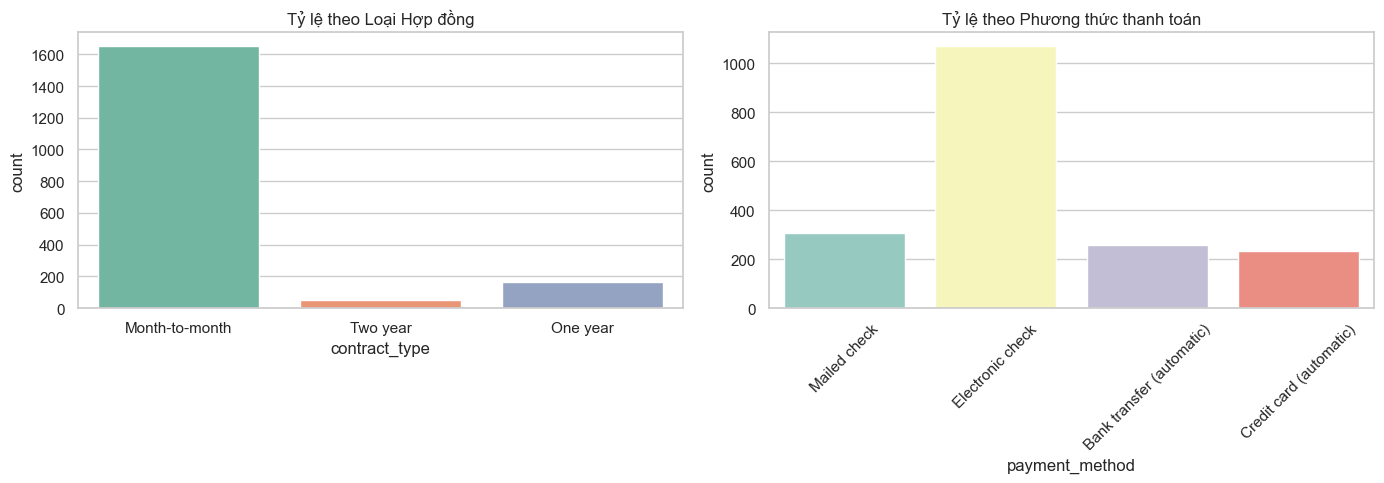

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x='contract_type', ax=axes[0], palette='Set2')
axes[0].set_title('Tỷ lệ theo Loại Hợp đồng')

sns.countplot(data=df, x='payment_method', ax=axes[1], palette='Set3')
axes[1].set_title('Tỷ lệ theo Phương thức thanh toán')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 5. Tương quan giữa các biến (Correlation)

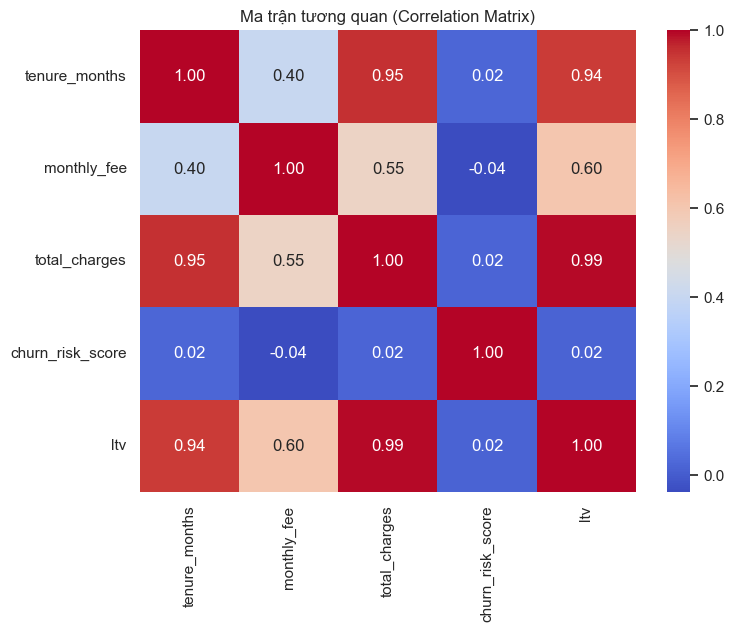

In [9]:
numeric_cols = ['tenure_months', 'monthly_fee', 'total_charges', 'churn_risk_score', 'ltv']
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Ma trận tương quan (Correlation Matrix)')
plt.show()

---
# Phân tích Dữ liệu Khách hàng có Nguy cơ cao (At-Risk Customers)
Phần này tập trung phân tích tập dữ liệu `at_risk_customers.csv`.

In [10]:
df_risk = pd.read_csv('data/at_risk_customers.csv')
print("Kích thước tập dữ liệu at-risk:", df_risk.shape)
display(df_risk.head())

Kích thước tập dữ liệu at-risk: (50, 10)


,customer_id,name,tenure_months,contract_type,payment_method,monthly_fee,total_charges,churn_risk_score,ltv,tier
0,3668-QPYBK,Hoàng Minh,2,Month-to-month,Mailed check,1292400.0,2595600.0,0.753713,1.570368e+07,Basic
1,9237-HQITU,Phạm Linh,2,Month-to-month,Electronic check,1696800.0,3639600.0,0.722478,1.689715e+07,Basic
2,9305-CDSKC,Huỳnh An,8,Month-to-month,Electronic check,2391600.0,19692000.0,0.731859,4.005722e+07,Standard
3,7892-POOKP,Hoàng Trang,28,Month-to-month,Electronic check,2515200.0,73105200.0,0.754181,9.384431e+07,VIP
4,0280-XJGEX,Trần Nam,49,Month-to-month,Bank transfer (automatic),2488800.0,120871200.0,0.872562,1.284981e+08,VIP


## 1. Phân bố Điểm rủi ro và Phân khúc (Tier)

D:\Temp\ipykernel_2508\1727044362.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_risk, x='tier', ax=axes[1], palette='pastel')


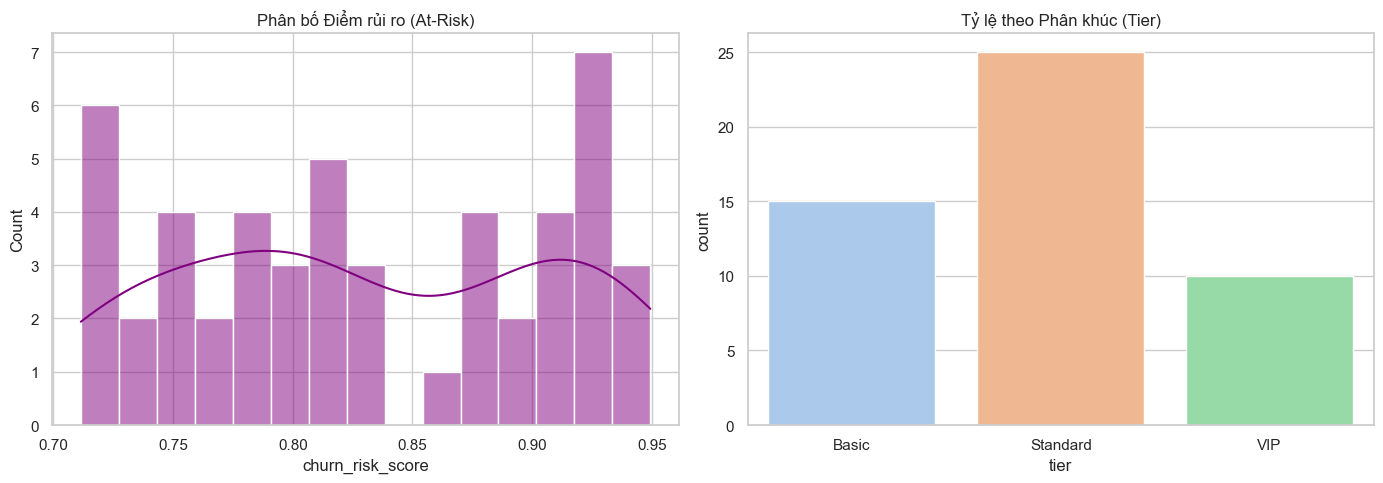

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_risk['churn_risk_score'], bins=15, kde=True, color='purple', ax=axes[0])
axes[0].set_title('Phân bố Điểm rủi ro (At-Risk)')

if 'tier' in df_risk.columns:
    sns.countplot(data=df_risk, x='tier', ax=axes[1], palette='pastel')
    axes[1].set_title('Tỷ lệ theo Phân khúc (Tier)')

plt.tight_layout()
plt.show()

## 2. Thống kê LTV theo Phân khúc (Tier)

D:\Temp\ipykernel_2508\2815085800.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_risk, x='tier', y='ltv', palette='Set2')


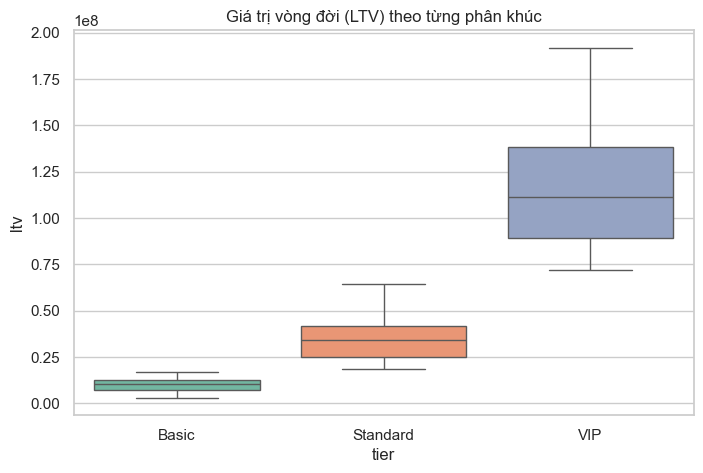

In [12]:
if 'tier' in df_risk.columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df_risk, x='tier', y='ltv', palette='Set2')
    plt.title('Giá trị vòng đời (LTV) theo từng phân khúc')
    plt.show()
else:
    print('Không có cột tier để hiển thị')